*Notebook 01 in `notebooks/arcs/`. Parameters (pre-registered): `analysis/arcs/config.yaml`; decisions and run notes: `analysis/arcs/LOG.md`. The static page `site/arcs/index.html` is built from the same saved outputs.*

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve().parents[1]   # notebooks/arcs -> repo root
sys.path.insert(0, str(REPO))

import warnings

import pandas as pd
import plotly.io as pio
from IPython.display import Markdown, display

from analysis.static_figures import use_static_figures

from analysis.arcs import s01_sample as step

use_static_figures()   # figures become static PNGs (they show on GitHub); interactive ones are on the static page
warnings.filterwarnings("ignore", category=RuntimeWarning)   # known 0/0 on very short arcs, handled downstream
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

## Step 1 · Sample and outcome

**What we do.** We rebuild the sample from the repo's own rules and check that it reproduces the feasibility
numbers before anything is measured. Then we describe the outcome, log(gross / budget), in the primary sample.

**The sample, step by step.**
- Clean theatrical films with US-dollar budget and gross and 100,000+ IMDb votes (the 10k tier is not used:
  its money isn't validated).
- Keep those with a MovieSum screenplay that has scene and dialogue markup.
- Drop the 8 scripts whose dialogue markup failed.
- The **primary sample** drops films that are likely part of a franchise (Wikidata "follows" or a named
  franchise). This choice was informed by the earlier word-level analysis, where the signal vanished without
  franchise films. We say this openly, and Steps 9 and 10 rerun everything with all scripts.

**Why a continuous outcome.** The earlier branch compared the bottom and top quarters of films, which threw
away the middle half of the data and the ordering inside each quarter. A correlation on the continuous
outcome uses every film, so it has more power at the same sample size.

**What it measures.** log(gross / budget): 0 means the film grossed its budget, 1 means about 2.7 times its
budget, 2 about 7.4 times. The log stops a few huge multiples from dominating.

**What it misses.** Gross / budget is **not profit**:
- Marketing isn't in the budget.
- Cinemas keep a large share of the gross.
- Nothing is adjusted for inflation. The ratio is still in consistent units, because budget and gross are in the
  same year's dollars.
- The ratio favours micro-budget films, horror especially: a cheap film can earn 50 times its budget, a
  blockbuster rarely more than 5.

In [2]:
res = step.run()   # recomputes this step and saves its outputs

**Table.** Sample funnel, rebuilt from the raw data and checked against the feasibility numbers (the 'expected' column). A mismatch would stop the analysis.

In [3]:
display(step.tables(res)["funnel"])

,stage,films,expected,note
0,"Clean theatrical USD films, 100k+ IMDb votes",2446,2446,scripts/imdb/coverage_clean_sample.sql
1,… with a usable MovieSum script (≥ 1 scene and ≥ 1 dialogue tag; longest of 12 duplicates),1095,1095,
2,… minus scripts whose dialogue markup failed (< 500 dialogue words),1087,1087,excluded: 8
3,"… not likely franchise (PRIMARY, before the arc-ready filter of Step 2)",868,868,"likely franchise: 219 (follows 146, named 133, both 60)"
4,Scripts with Tag Genome reviews (Step 11 frame),946,946,no film after 2017
5,… not likely franchise,759,759,


**Figure.** Distribution of log(gross/budget) for all clean films (grey), the primary sample (blue, hatched) and the franchise films we set aside (orange, crossed). Bars are shares of each sample. Compare the blue with the grey: if the primary sample were a narrow, hit-only slice, its bars would sit to the right of the grey and be narrower. The table below gives the numbers.

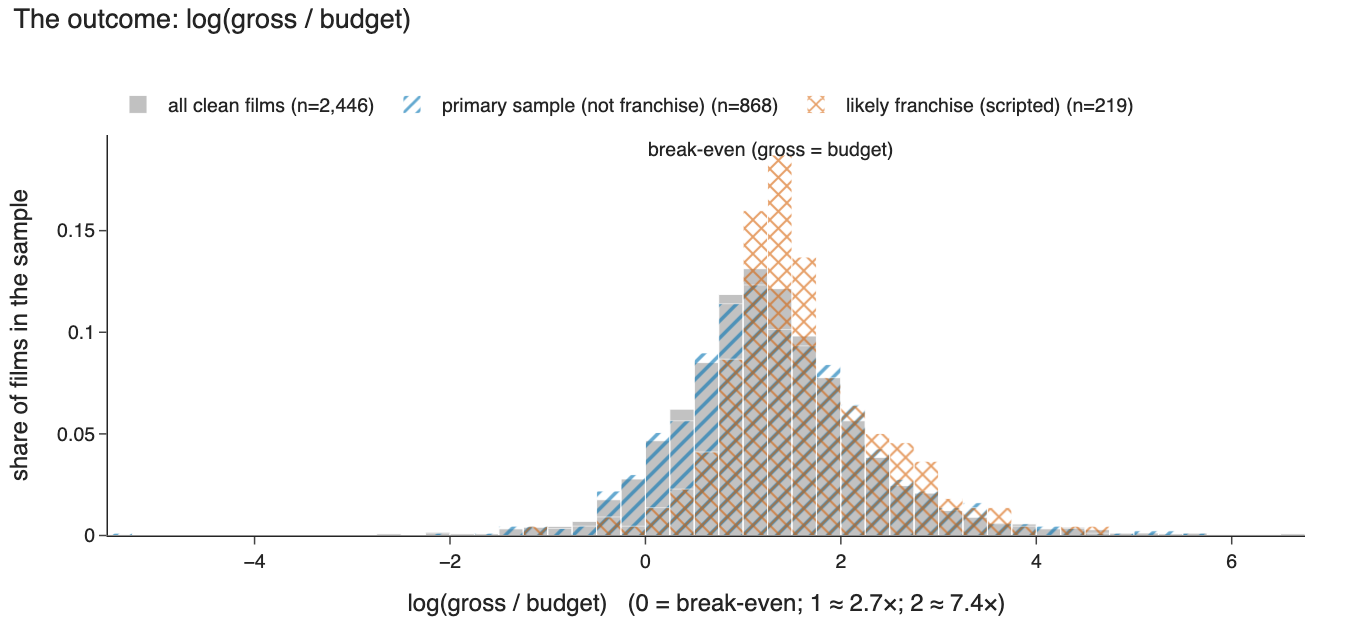

In [4]:
step.figures(res)["outcome"].show()

**Table.** The outcome in three samples: spread (SD), range, quartiles and the share of films that grossed less than their budget.

In [5]:
display(step.tables(res)["outcome"])

,sample,films,mean,SD,min,Q1,Q3,max,share gross < budget,median multiple (×)
0,all clean films,2446,1.294,1.026,-6.06,0.71,1.79,6.73,0.069,3.41
1,"scripted (1,087)",1087,1.379,1.006,-5.28,0.79,1.90,5.53,0.062,3.69
2,primary: not franchise,868,1.323,1.040,-5.28,0.70,1.86,5.53,0.073,3.45


**Table.** Does the script sample lean towards hits? Counts of films in the bottom and top quarters used by the earlier branch (cut-offs from all 2,446 clean films), for all scripted films and for the primary sample. With no lean the two counts would be about equal (top / bottom ≈ 1).

In [6]:
display(step.tables(res)["skew"])

,sample,earlier definition,bottom quarter (scripts),top quarter (scripts),top / bottom
0,"scripted (1,087)",B: quarters of all clean films,242,304,1.26
1,"scripted (1,087)",C: quarters within genre × decade cells,236,290,1.23
2,primary: not franchise,B: quarters of all clean films,223,235,1.05
3,primary: not franchise,C: quarters within genre × decade cells,220,213,0.97


**Figure.** Budget of the primary films, log scale. Budgets range from under a million to hundreds of millions, which is why log budget is a control.

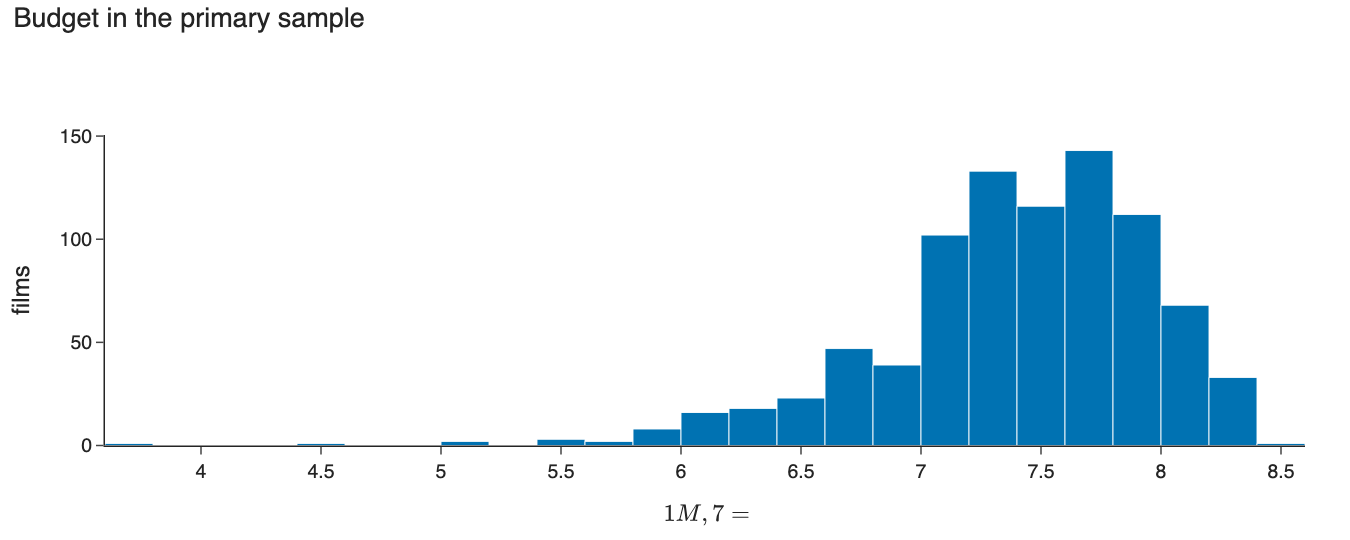

In [7]:
step.figures(res)["budget"].show()

**Figure.** Each dot is a primary film: budget (x) against log(gross/budget) (y). The spread in y is much wider for cheap films, so budget has to be controlled before anything else is related to the outcome.

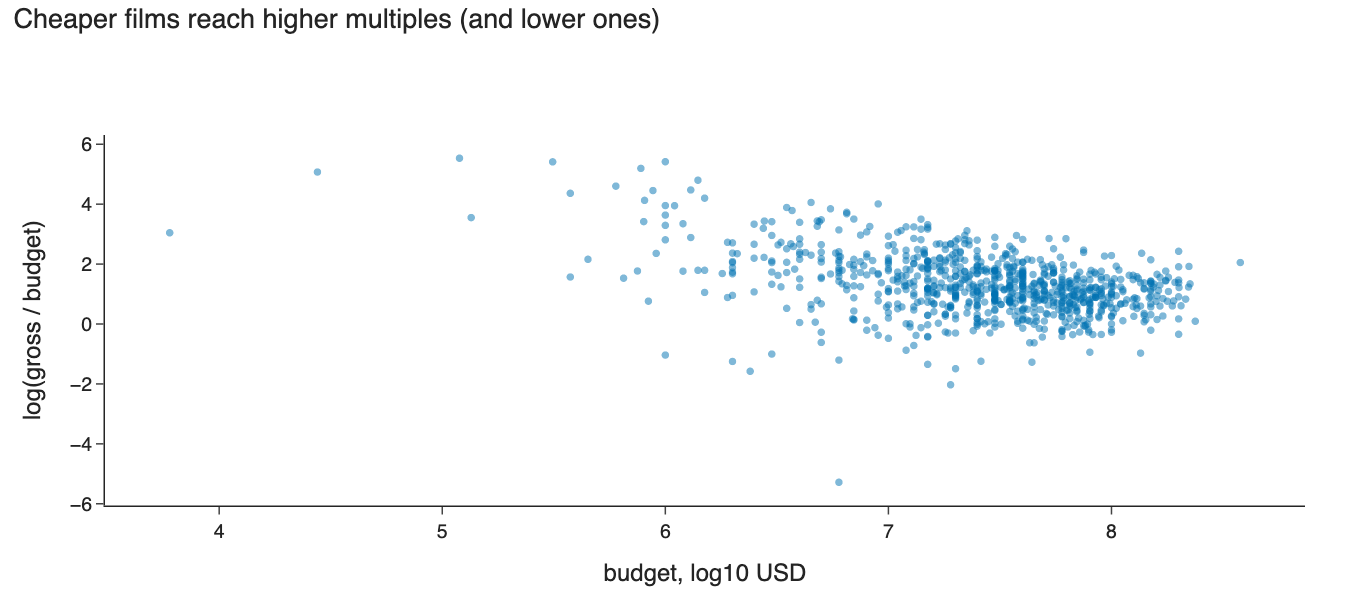

In [8]:
step.figures(res)["budget_vs_outcome"].show()

**Table.** Budget percentiles for the scripted films, the primary sample and the franchise films. Franchise films are much more expensive, one reason to treat them separately.

In [9]:
display(step.tables(res)["budget"])

,sample,films,P10 ($M),P25 ($M),P50 ($M),P75 ($M),P90 ($M),median log(gross/budget)
0,"scripted (1,087)",1087,5.0,15.0,35.0,75.0,140.0,1.305
1,primary: not franchise,868,4.5,13.2,30.0,62.1,102.0,1.238
2,likely franchise,219,12.8,29.0,69.0,141.2,200.0,1.455


**Figure.** Number of primary films in each primary-genre × decade cell (the fixed effects of the analysis). Genre uses the frozen priority rule (Horror, Sci-Fi, Thriller, Adventure, Action, Comedy, Drama). Cells with fewer than 5 films are pooled, so no film is compared only with itself.

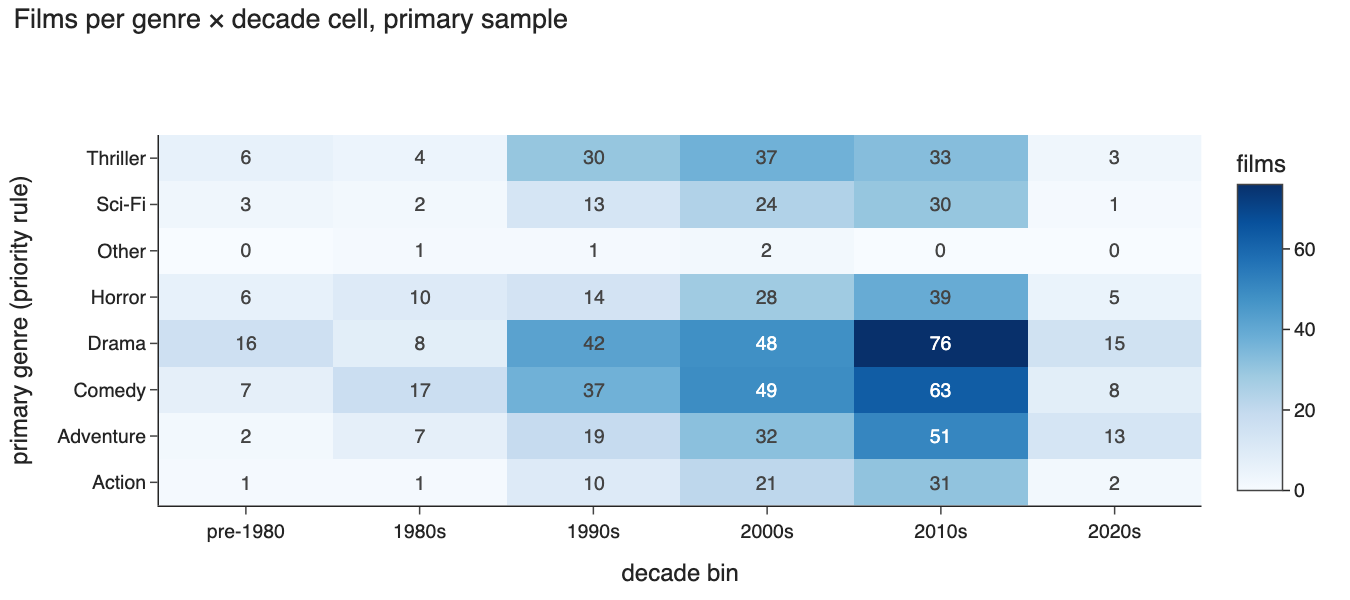

In [10]:
step.figures(res)["cells"].show()

**Table.** The same counts as a table.

In [11]:
display(step.tables(res)["composition"])

decade_bin,primary genre,pre-1980,1980s,1990s,2000s,2010s,2020s,all
0,Action,1,1,10,21,31,2,66
1,Adventure,2,7,19,32,51,13,124
2,Comedy,7,17,37,49,63,8,181
3,Drama,16,8,42,48,76,15,205
4,Horror,6,10,14,28,39,5,102
5,Other,0,1,1,2,0,0,4
6,Sci-Fi,3,2,13,24,30,1,73
7,Thriller,6,4,30,37,33,3,113
8,all,41,50,166,241,323,47,868


**Plain-language reading** (generated from the saved numbers):

In [12]:
display(Markdown(step.reading(res)))

All six funnel numbers reproduce the feasibility note (2,446, 1,095, 1,087, 868, 946, 759). The scripted films lean towards hits: median multiple 3.69× against 3.41× for all clean films, and 304 scripts in the top quarter against 242 in the bottom (290 vs 236 within cells). Most of that lean comes from franchise films: in the primary sample the counts are 235 vs 223 (213 vs 220 within cells), the median multiple is 3.45×, 7.3% grossed less than their budget (all clean films: 6.9%) and the SD of log(gross/budget) is 1.04 (all clean films: 1.03). So the restricted range the brief expects is small in the primary sample: it is mainly a property of the scripted sample as a whole. The selection is still not random: these are films popular enough for 100,000+ IMDb votes and a public screenplay. After genre × decade cells and log budget the SD left to explain is 0.91. 23 primary films sit in cells with fewer than 5 films and are pooled (36 cells in all). Tag Genome reviews stop at 2017.